# Data Workflow

The following notebook showcases the tools and estimation that can be done on synthetic data using NOCAP.

1. Synthetic data generation
2. Data artifacts
3. Binarization of scRNA-seq data
4. Binary interventions
5. Cyclic query identification and binary ATE estimation
6. Continuous distribution-based ATE estimation

## Graph Setup

This section defines a small directed gene-regulatory network with a three-node feedback cycle and a shared downstream target.

In [180]:
import networkx as nx

In [181]:
small_network = [
    ("TF1", "TF2"),
    ("TF2", "TF3"),
    ("TF3", "TF1"),
    ("TF1", "G1"),
    ("TF2", "G1"),
    ("TF3", "G1"),
]
graph = nx.DiGraph(small_network)

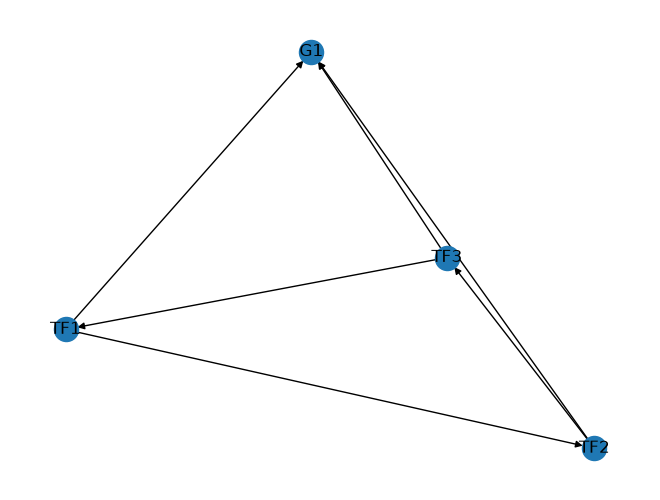

In [182]:
nx.draw(graph, with_labels=True, pos=nx.spring_layout(graph))

## Synthetic Data Generation

This section builds a stable linear SCM on the graph and simulates both latent expression and UMI observations. The configured binary expression state records ground-truth ON/OFF activity, while the count layer adds realistic sampling/measurement variation.

In [183]:
import matplotlib.pyplot as plt
import numpy as np

from nocap.scm_model import build_synthetic_scm
from nocap.simulation import SimulationConfig, generate_from_scm, simulate_expression_treatment

In [184]:
seed = 42

In [185]:
config = SimulationConfig(
    n_samples=10_000,
    estimation_graph=graph,
    use_latent_expression_hat=False,
    use_umi_counts_as_observed_data=False,
    use_binary_expression_state=True
)

In [186]:
nodes = sorted(graph.nodes())
scm = build_synthetic_scm(
    graph,
    nodes,
    missing_edge_rate=0.0,
    beta_med=0.5,
    beta_log_sd=1,
    beta_p=0.5,
    beta_abs_max=5.0,
    rng=np.random.default_rng(seed),
).scm

In [187]:
print("Generated SCM beta values:")
for (source, target), beta in scm.betas.items():
    print(f"{source} -> {target}: {beta:.4f}")

Generated SCM beta values:
TF1 -> TF2: -0.6781
TF1 -> G1: -0.1767
TF2 -> TF3: 1.0590
TF2 -> G1: 1.2807
TF3 -> TF1: 0.0711
TF3 -> G1: -0.1360


In [188]:
observational = generate_from_scm(
    scm,
    config,
    rng=np.random.default_rng(seed + 1)
)

In [189]:
assert observational.latent_log_expression is not None
assert observational.latent_expression_state is not None
assert observational.umi_counts is not None

In [190]:
scm.nodes

('G1', 'TF1', 'TF2', 'TF3')

In [191]:
observational.latent_expression_state

array([[ True,  True,  True, False],
       [False, False, False, False],
       [ True,  True,  True, False],
       ...,
       [ True, False,  True,  True],
       [False, False,  True, False],
       [ True, False,  True,  True]], shape=(10000, 4))

In [192]:
observational.latent_log_expression

array([[-0.81127992,  0.54188767, -0.95299458, -1.91787314],
       [-2.8911629 ,  0.93954969, -0.62047072, -0.45133331],
       [-0.85681869,  1.22624369,  0.11165944, -0.00357902],
       ...,
       [ 0.14024554, -0.71530418, -0.28447757, -0.52866614],
       [-0.04460655, -0.29871662, -0.5645901 , -1.67373034],
       [ 2.49591005, -0.84360215,  2.11616031,  1.44133847]],
      shape=(10000, 4))

In [193]:
observational.umi_counts

array([[ 0, 10,  1,  0],
       [ 0,  0,  0,  0],
       [ 1,  6,  1,  0],
       ...,
       [ 0,  0,  1,  4],
       [ 0,  0,  0,  0],
       [ 9,  0,  3,  4]], shape=(10000, 4))

In [194]:
observational.umi_counts.mean()

np.float64(2.051375)

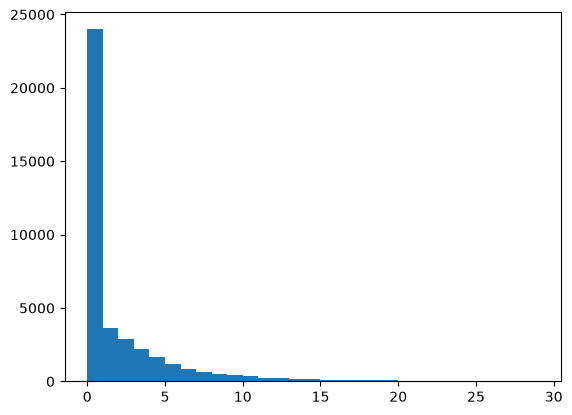

In [195]:
# Skewed data
p = plt.hist(observational.umi_counts.flatten(), bins=range(30))

## Binarization of scRNA-seq data

scBoolSeq converts normalized, log-transformed UMI measurements into gene-level ON/OFF calls. Here zero counts are assigned OFF so every result can be compared with the simulated latent activity labels. The per-gene agreement table shows where observed-data binarization recovers biological state and where count noise or classification uncertainty causes disagreement.

In [196]:
import pandas as pd

from nocap.binarization import binarize_expression

In [197]:
# Preprocess
log_normalized_expression = pd.DataFrame(np.log1p(observational.umi_counts / observational.size_factors[:, None]), columns=scm.nodes)

In [198]:
binary = binarize_expression(
    log_normalized_expression,
    unknown='off',
    binarizer_kwargs={
        "zeroes_are": 0.0
    }
).to_numpy()

In [199]:
scm.nodes

('G1', 'TF1', 'TF2', 'TF3')

In [200]:
latent_state = observational.latent_expression_state
matches = binary.astype(bool) == latent_state

print(f"Overall agreement: {matches.mean():.2%}")
print(f"Number of differing entries: {(~matches).sum()}")

pd.DataFrame(
    {
        "agreement": matches.mean(axis=0),
        "differences": (~matches).sum(axis=0),
    },
    index=scm.nodes,
)

Overall agreement: 90.59%
Number of differing entries: 3765


,agreement,differences
G1,0.8772,1228
TF1,0.9571,429
TF2,0.8516,1484
TF3,0.9376,624


## Paired Data Artifacts

A paired artifact stores one reproducible maximum-size realization that can be viewed at smaller sample sizes without regenerating its underlying observations. This makes comparisons across sample-size conditions fair by sharing samples and observation noise. The artifact exposes continuous observations, binarized calls, and latent truth aligned to the same sample subset.

In [201]:
from nocap.simulation import generate_paired_data_artifact

In [202]:
artifact = generate_paired_data_artifact(
    scm,
    config,
    max_samples=100_000,
    scm_seed=seed,
    data_seed=seed + 1,
    binarize=True,
    unknown='off',
    binarizer_kwargs={
        "zeroes_are": 0.0
    }
)

/Users/colin.pannikkat/projects/nocap/.venv/lib/python3.14/site-packages/diptest/consts.py:702: UserWarning: Sample size exceeds the maximum limit of 72000. Results may not be accurate with precomputed statistical values.
  warnings.warn(


In [203]:
modified_config = SimulationConfig(
    n_samples=6,  # smaller number of samples, which is a subset of the larger data
    use_umi_counts_as_observed_data=True
)

In [204]:
artifact.view(modified_config)

,G1,TF1,TF2,TF3
0,17,0,4,3
1,4,0,4,4
2,2,0,5,7
3,0,7,0,0
4,19,0,0,0
5,0,1,1,0


In [205]:
artifact.binarized_view(modified_config).astype(bool)

,G1,TF1,TF2,TF3
0,True,False,True,True
1,True,False,True,True
2,True,False,True,True
3,False,True,False,False
4,True,False,False,False
5,False,True,True,False


In [206]:
artifact.latent_expression_state_view(modified_config)

,G1,TF1,TF2,TF3
0,True,False,True,True
1,True,False,True,True
2,True,False,True,True
3,False,True,False,False
4,True,False,True,False
5,True,True,True,False


## Binary Expression Treatments (A/I/K)

`simulate_expression_treatment` models activation (A), interference (I), and knockout (K) by removing incoming edges to the target and preserving its outgoing effects. A fixes latent expression at the configured activation level and clamps the state ON. I lowers latent expression but leaves the ON/OFF state stochastic under the configured expression-state model; it does not clamp the target ON. K lowers latent expression and clamps the state OFF. Comparing latent expression, ON fraction, and counts shows how each perturbation changes both expression level and observed activity.

In [207]:
# Compare each supported treatment at the same target gene.
treatment_states = {
    treatment: simulate_expression_treatment(
        scm, config, target="TF1", treatment=treatment, seed=seed + 10 + index
    )
    for index, treatment in enumerate(("A", "I", "K"))
}

target_index = scm.nodes.index("TF1")
pd.DataFrame(
    {
        treatment: {
            "latent log2 expression": state.latent_log_expression[:, target_index].mean(),
            "fraction ON": state.latent_expression_state[:, target_index].mean(),
            "mean UMI count": state.umi_counts[:, target_index].mean(),
        }
        for treatment, state in treatment_states.items()
    }
)

,A,I,K
latent log2 expression,1.0000,-3.321928,-6.643856
fraction ON,1.0000,0.035600,0.000000
mean UMI count,2.1726,0.003700,0.000000


## Estimate a Continuous ATE from an Identified Distribution

For continuous observations, NOCAP can estimate an ATE either by evaluating the identified probability expression with KDE or directly from a causal graph using cyclic single-door (CSD) edge estimates (only valid on latent values). `estimated_scm_ate` determines adjustment sets from the supplied graph, estimates its edge coefficients from observational data, assembles an estimated SCM, and simulates its ATE. The comparison below checks both estimates against the known SCM reference.

In [213]:
from nocap.estimation import estimated_scm_ate
from nocap.simulation import true_scm_ate

continuous_graph = nx.DiGraph([ ("T", "Y") ])
continuous_scm = build_synthetic_scm(
    continuous_graph,
    ["T", "Y"],
    missing_edge_rate=0.0,
    beta_med=0.5,
    beta_log_sd=1,
    beta_p=0.5,
    beta_abs_max=5.0,
    rng=np.random.default_rng(seed + 30),
).scm
continuous_config = SimulationConfig(n_samples=5_000)
continuous_state = generate_from_scm(
    continuous_scm, continuous_config, rng=np.random.default_rng(seed + 31)
)
continuous_data = pd.DataFrame(
    continuous_state.latent_log_expression, columns=continuous_scm.nodes
)
continuous_expression = identify_causal_query(continuous_graph, {"T"}, {"Y"})
treatment_levels = (-0.5, 0.5)
estimated_ate = estimate_distribution_ate(
    continuous_expression,
    continuous_data,
    treatment="T",
    outcome="Y",
    treatment_levels=treatment_levels,
    mode="continuous",
    outcome_bounds=(-np.inf, np.inf),
    legendre_degree=64,
)
reference_ate = true_scm_ate(
    continuous_scm, "T", "Y", treatment_levels, n_samples=20_000, seed=seed + 32
)
graph_ate, edge_estimates, estimated_scm = estimated_scm_ate(
    continuous_graph,
    continuous_data,
    treatment="T",
    outcome="Y",
    treatment_levels=treatment_levels,
    n_samples=20_000,
    seed=seed + 33,
)
print("Graph-based CSD edge estimates:")
edge_estimate_table = pd.DataFrame(
    [
        {"edge": f"{item.cause} -> {item.effect}", "status": item.status, "coefficient": item.coefficient, "rows": item.n_rows}
        for item in edge_estimates
    ]
)
ate_comparison = pd.DataFrame(
    {
        "estimate": [estimated_ate, graph_ate, reference_ate],
    },
    index=["Identified distribution + KDE", "Graph + CSD edge estimates", "Known SCM reference"],
)
ate_comparison["absolute error vs SCM"] = (
    ate_comparison["estimate"] - reference_ate
).abs()
display(edge_estimate_table)
ate_comparison

Graph-based CSD edge estimates:


,edge,status,coefficient,rows
0,T -> Y,estimated,0.190916,5000


,estimate,absolute error vs SCM
Identified distribution + KDE,0.189453,0.006124
Graph + CSD edge estimates,0.190916,0.007587
Known SCM reference,0.183329,0.000000
